In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Urban           Y  
1             1.0         Rural           N  
2             1.0   

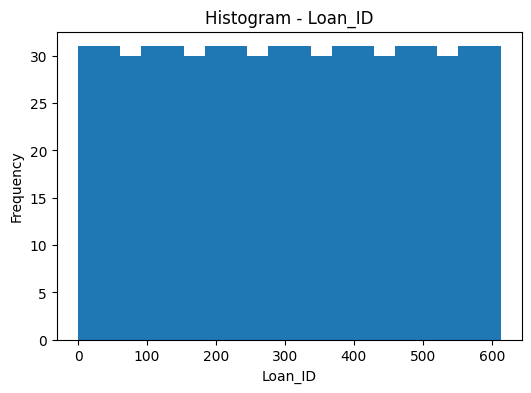

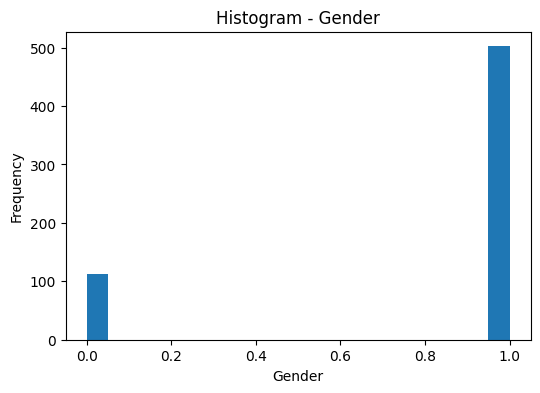

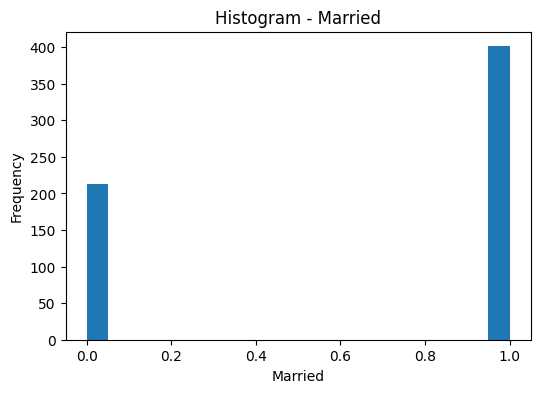

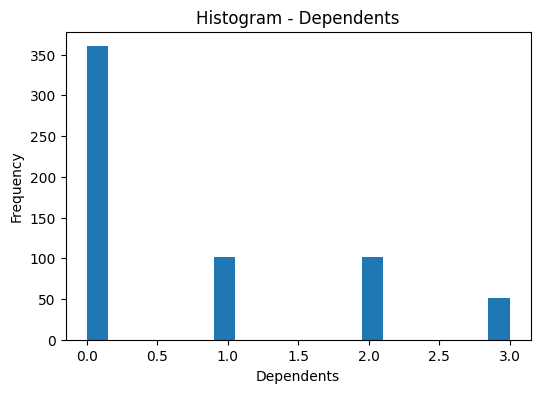

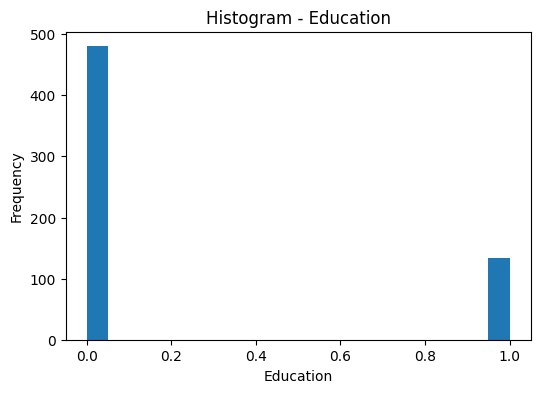

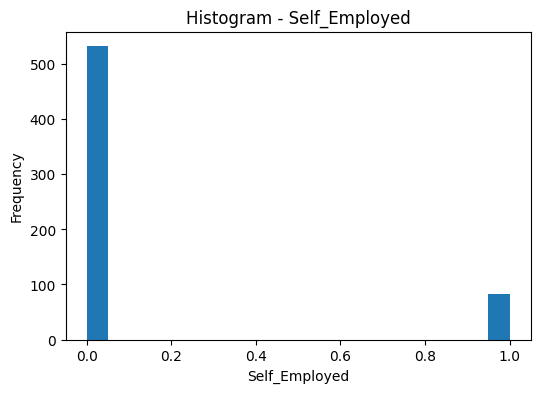

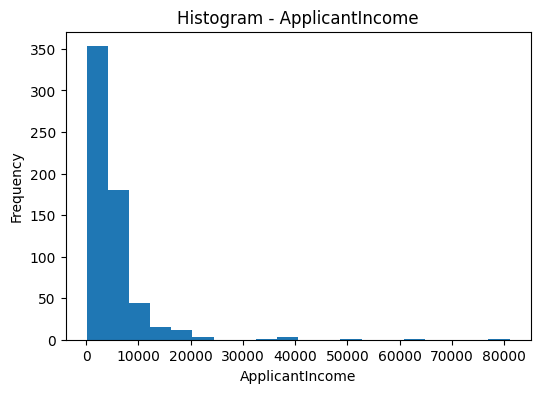

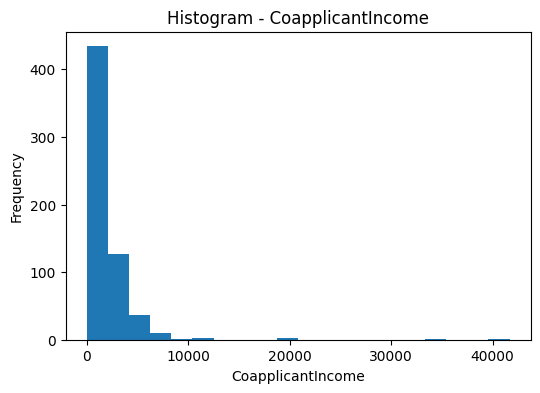

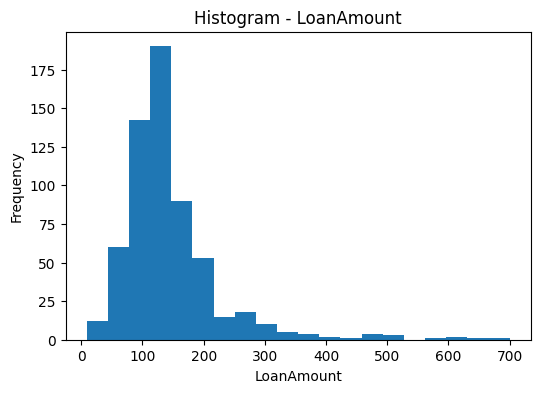

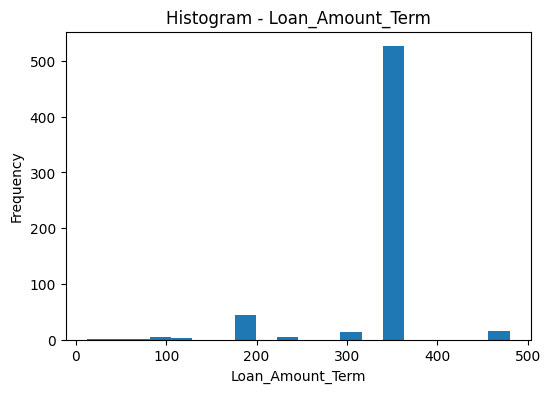

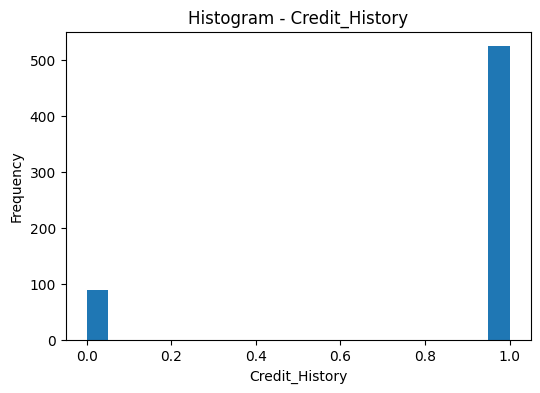

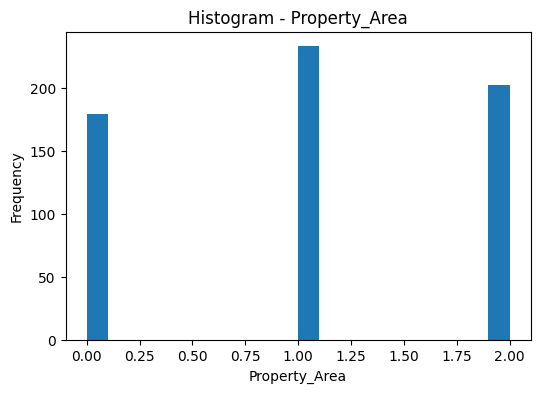

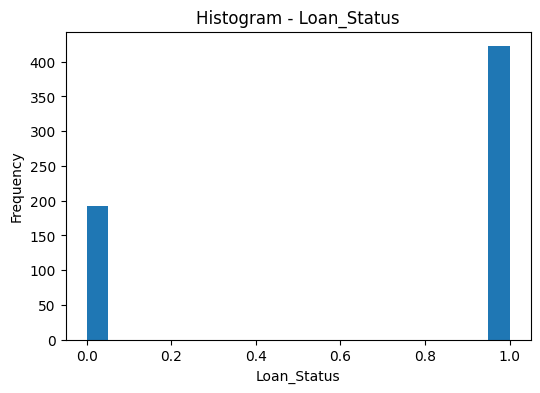

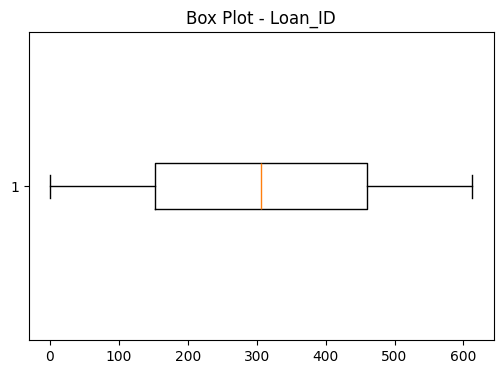

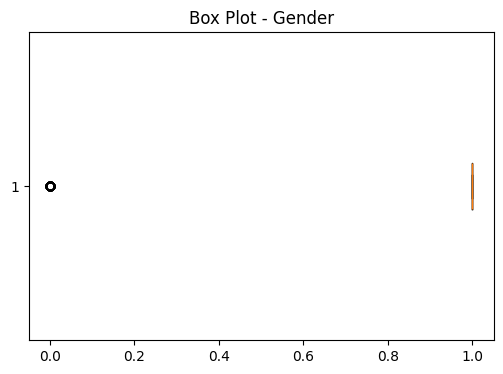

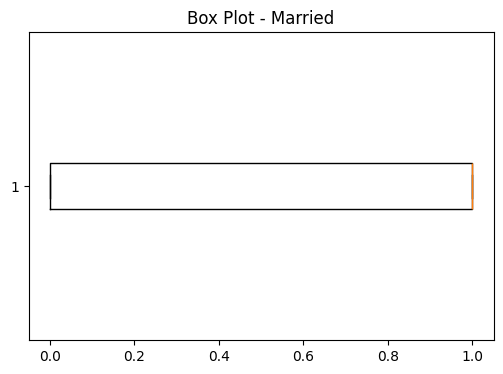

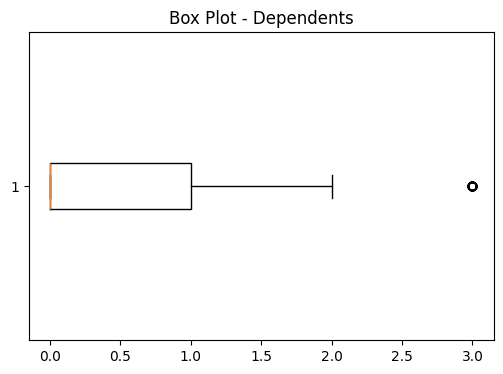

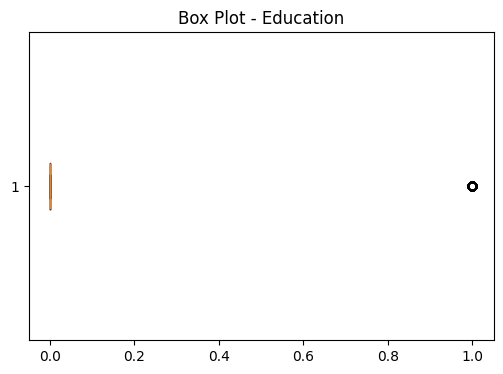

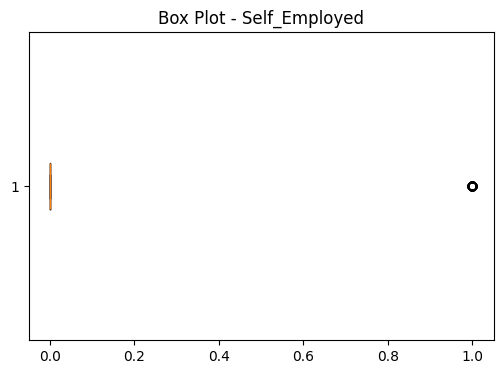

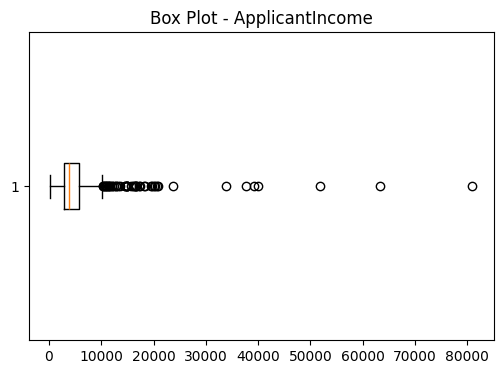

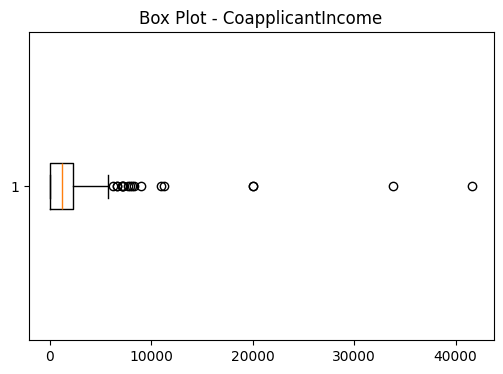

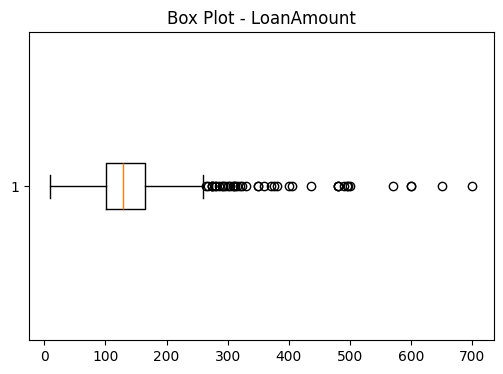

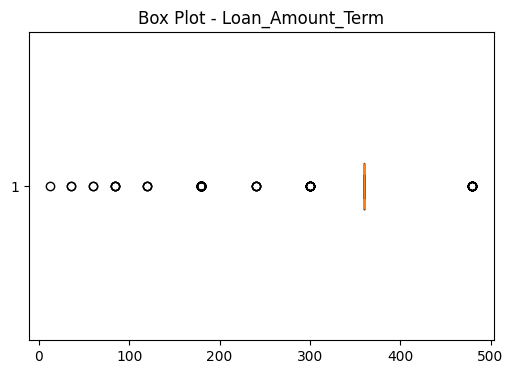

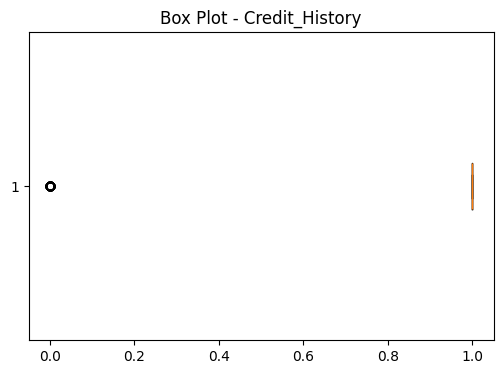

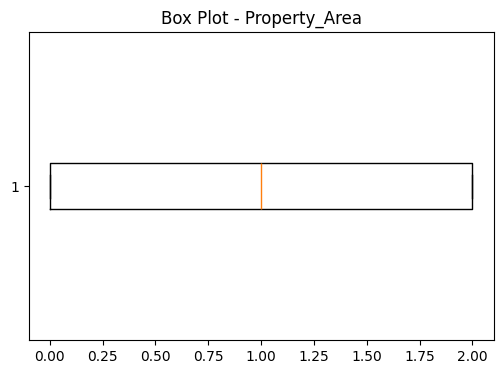

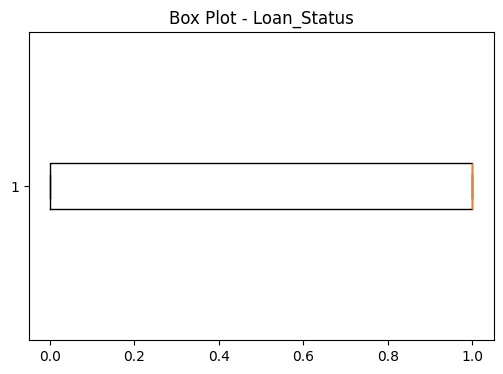

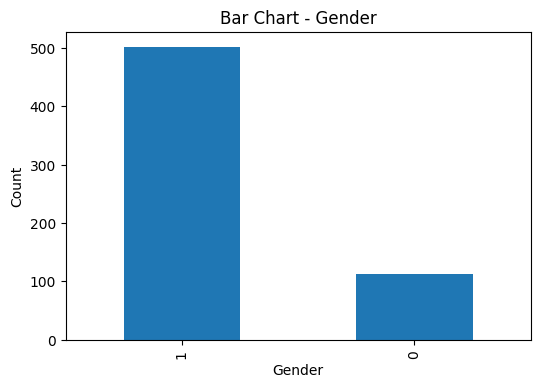

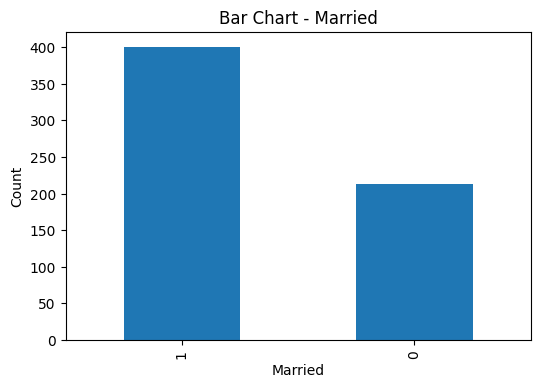

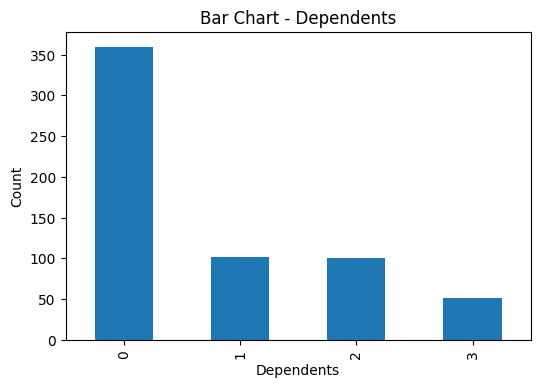

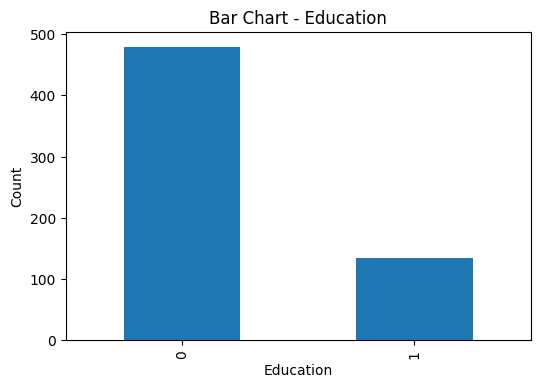

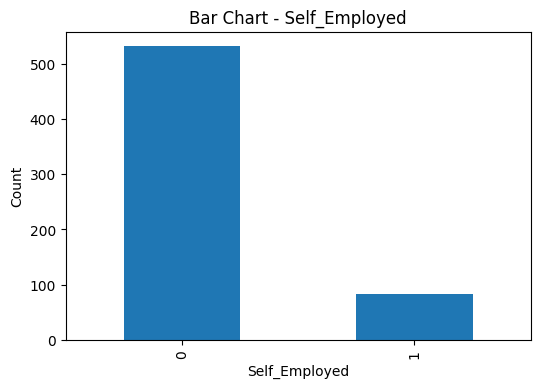

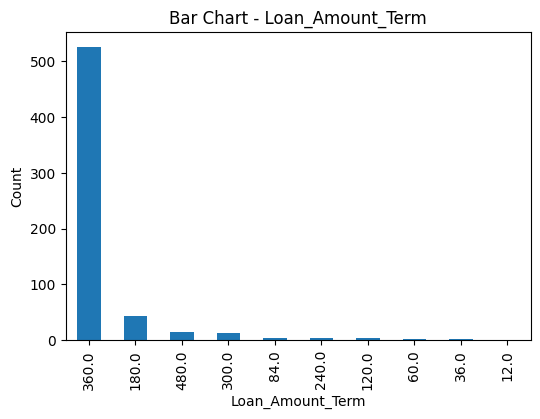

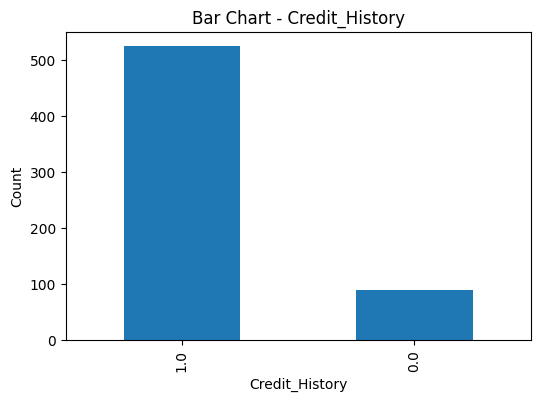

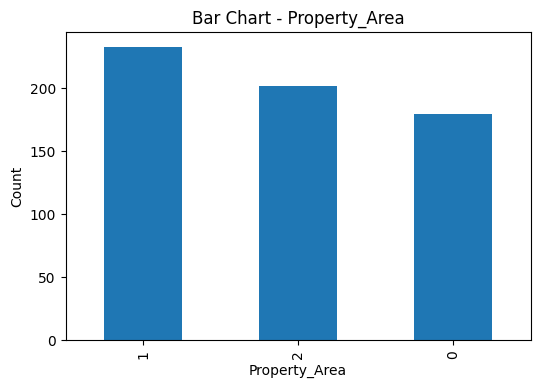

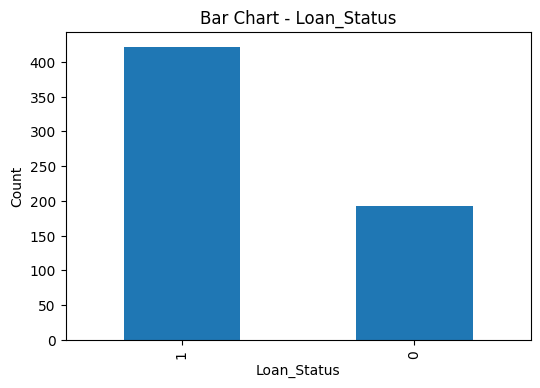

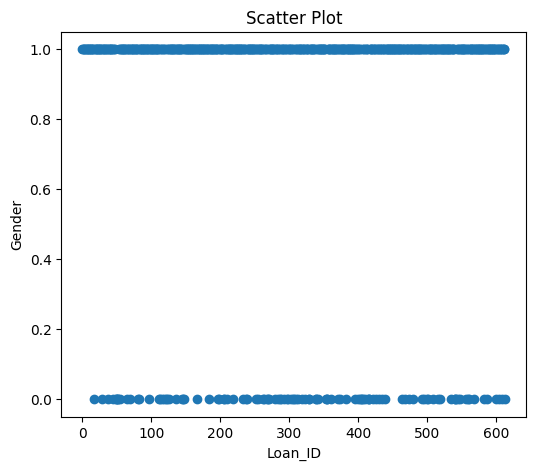

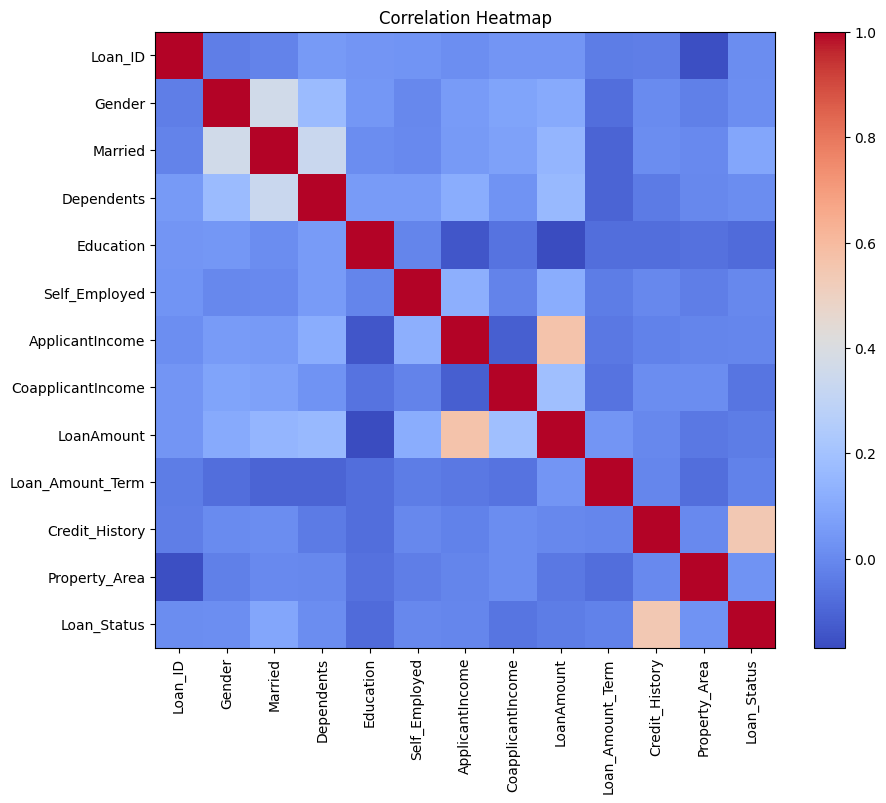

Loan_ID = 0 outliers
Gender = 112 outliers
Married = 0 outliers
Dependents = 51 outliers
Education = 134 outliers
Self_Employed = 82 outliers
ApplicantIncome = 50 outliers
CoapplicantIncome = 18 outliers
LoanAmount = 41 outliers
Loan_Amount_Term = 88 outliers
Credit_History = 89 outliers
Property_Area = 0 outliers
Loan_Status = 0 outliers

Standardized Data
    Loan_ID    Gender   Married  Dependents  Education  Self_Employed  \
0 -1.729232  0.472343 -1.372089   -0.737806  -0.528362      -0.392601   
1 -1.723590  0.472343  0.728816    0.253470  -0.528362      -0.392601   
2 -1.717948  0.472343  0.728816   -0.737806  -0.528362       2.547117   
3 -1.712307  0.472343  0.728816   -0.737806   1.892641      -0.392601   
4 -1.706665  0.472343 -1.372089   -0.737806  -0.528362      -0.392601   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0         0.072991          -0.554487   -0.211241          0.273231   
1        -0.134412          -0.038732   -0.211241          

In [ ]:
path="loan.csv"
df=pd.read_csv(path)

print(df.head())
print(df.tail())
print(df.shape)
print(df.columns)
print(df.dtypes)
print(df.info())
print(df.describe(include='all'))
print("\nDuplicate Rows :", df.duplicated().sum())
print("\nMISSING VALUES")
missing=pd.DataFrame({"Missing Values": df.isnull().sum(),"Percentage": (df.isnull().sum()/len(df)) * 100})
print(missing)


for col in df.columns:
    if df[col].dtype=="object":
        df[col]=df[col].fillna(df[col].mode()[0])
    else:
        df[col]=df[col].fillna(df[col].median())

print("\nMissing values after preprocessing")
print(df.isnull().sum())

label_encoder=LabelEncoder()
for col in df.select_dtypes(include="object").columns:
    df[col] = label_encoder.fit_transform(df[col])

print("\nCategorical variables encoded.")
numerical=df.select_dtypes(include=np.number).columns
categorical=df.select_dtypes(exclude=np.number).columns

print("\nNumerical Features")
print(numerical)

print("\nCategorical Features")
print(categorical)

for col in numerical:
    plt.figure(figsize=(6, 4))
    plt.hist(df[col], bins=20)
    plt.title(f"Histogram - {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

for col in numerical:
    plt.figure(figsize=(6, 4))
    plt.boxplot(df[col], vert=False)
    plt.title(f"Box Plot - {col}")
    plt.show()

for col in df.columns:
    if df[col].nunique()<=15:
        plt.figure(figsize=(6, 4))
        df[col].value_counts().plot(kind="bar")
        plt.title(f"Bar Chart - {col}")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.show()

if len(numerical)>=2:
    plt.figure(figsize=(6, 5))
    plt.scatter(df[numerical[0]], df[numerical[1]])
    plt.xlabel(numerical[0])
    plt.ylabel(numerical[1])
    plt.title("Scatter Plot")
    plt.show()

corr=df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", aspect="auto")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap")
plt.show()

for col in numerical:
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
    IQR=Q3-Q1
    lower=Q1-1.5*IQR
    upper=Q3+1.5*IQR
    outliers=df[(df[col]<lower)|(df[col]>upper)]
    print(col,"=",len(outliers),"outliers")

standard_scaler = StandardScaler()
standardized=standard_scaler.fit_transform(df[numerical])
standardized_df=pd.DataFrame(standardized,columns=numerical)
print("\nStandardized Data")
print(standardized_df.head())

minmax = MinMaxScaler()
normalized = minmax.fit_transform(df[numerical])
normalized_df = pd.DataFrame(normalized,columns=numerical)
print("\nNormalised Data")
print(normalized_df.head())


   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
763           10      101             76             48      180  32.9   
764            2      122             70             27        0  36.8   
765            5      121             72             23      112  26.2   
766    

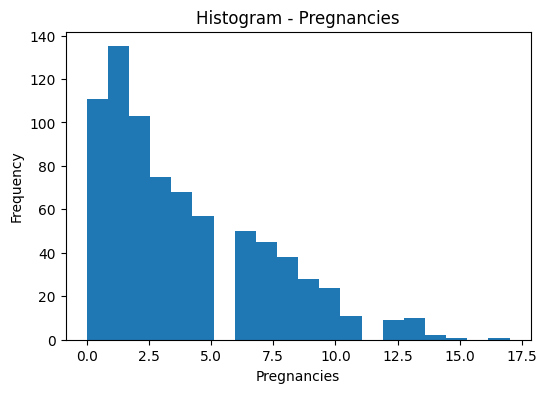

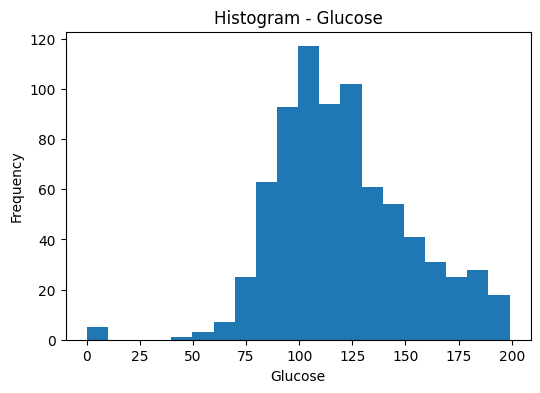

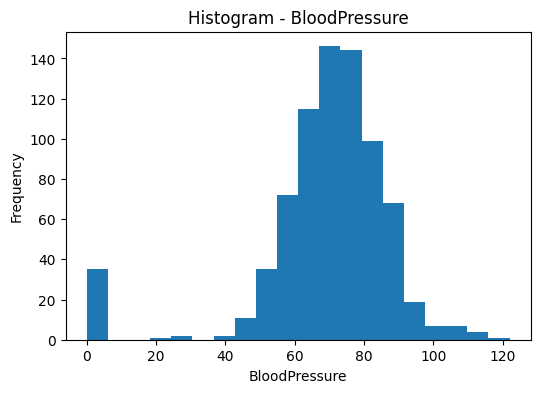

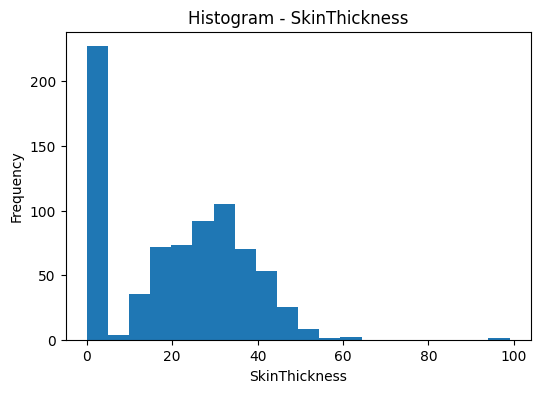

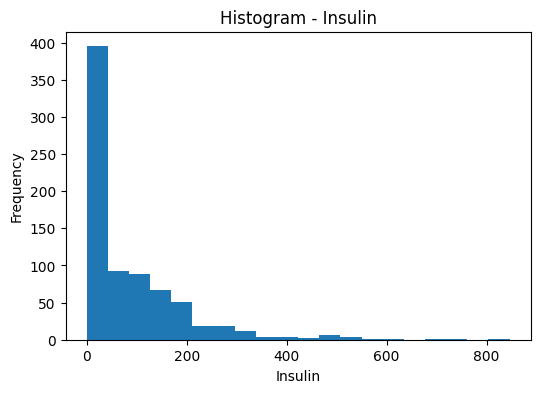

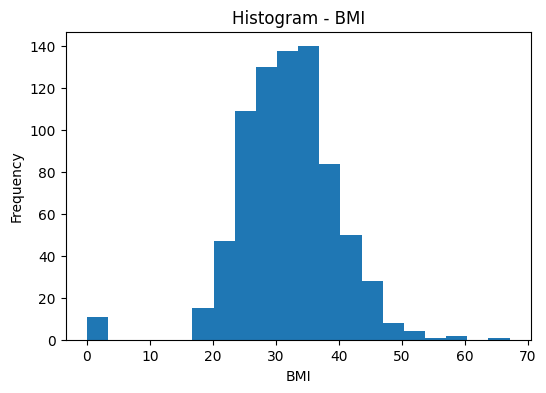

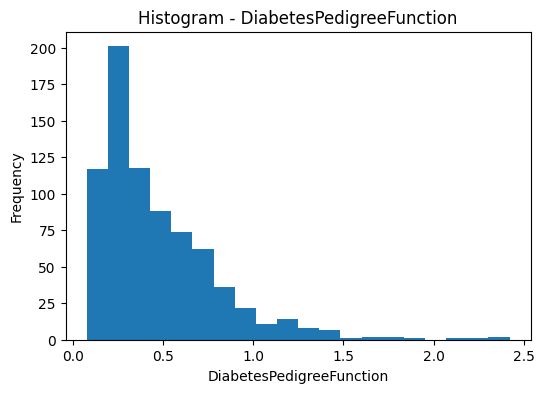

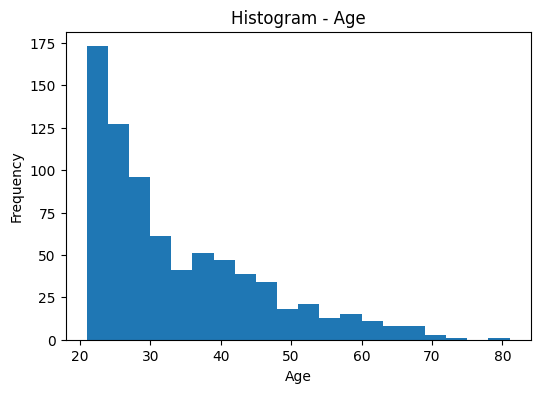

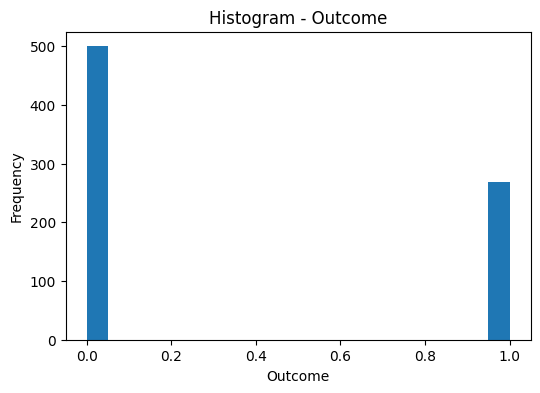

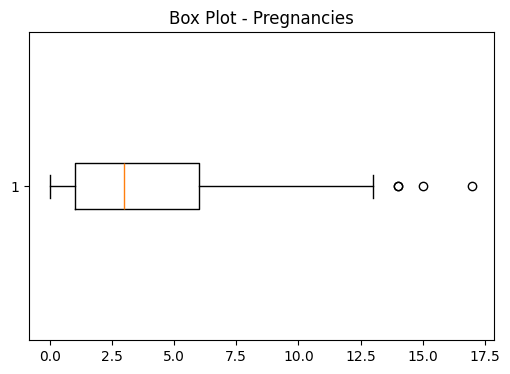

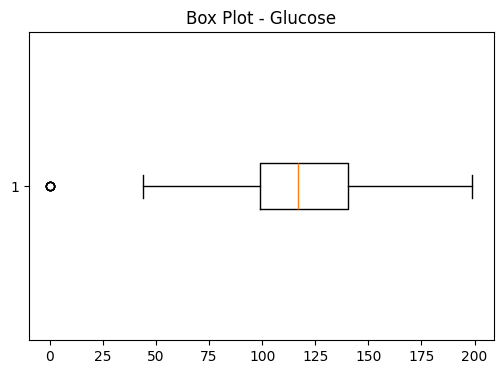

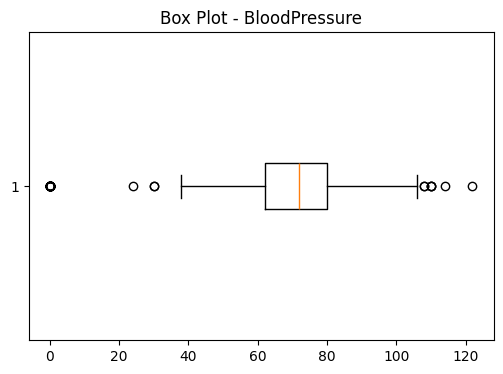

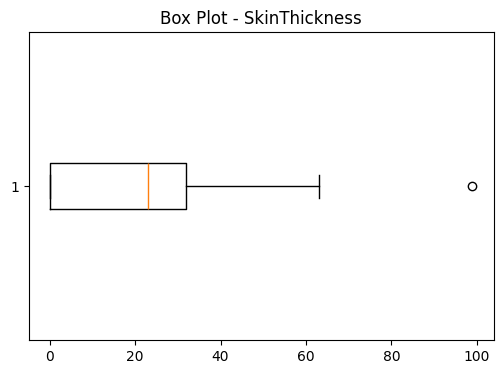

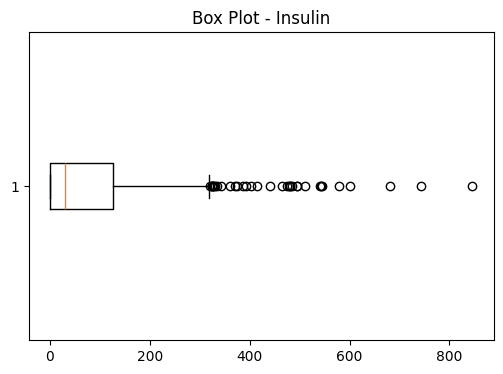

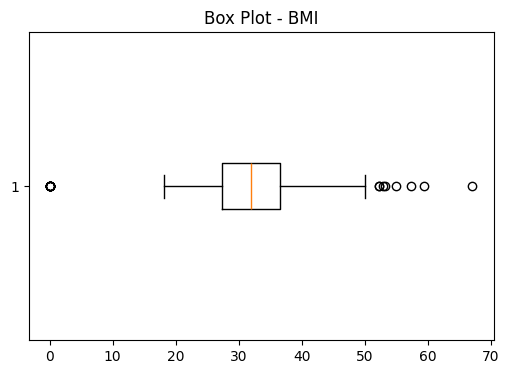

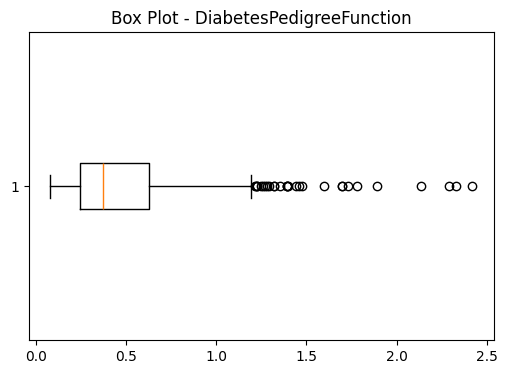

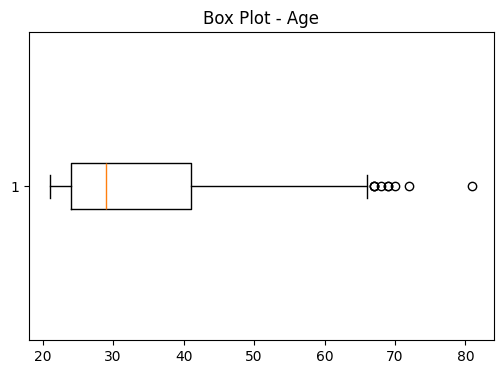

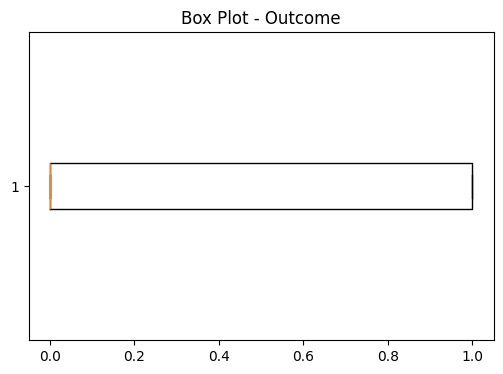

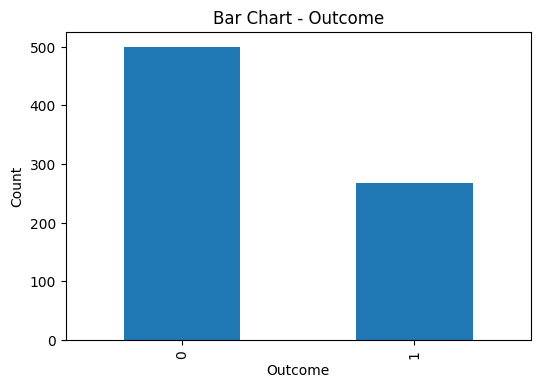

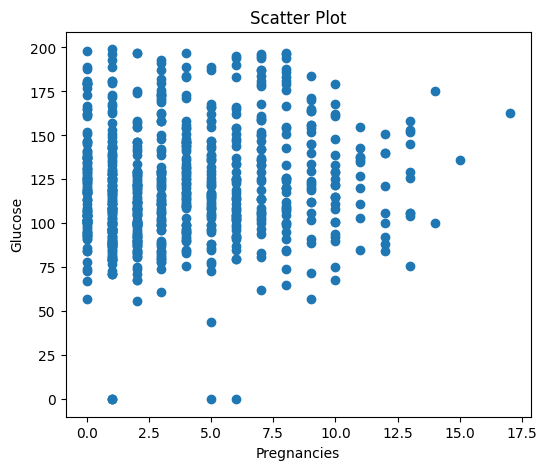

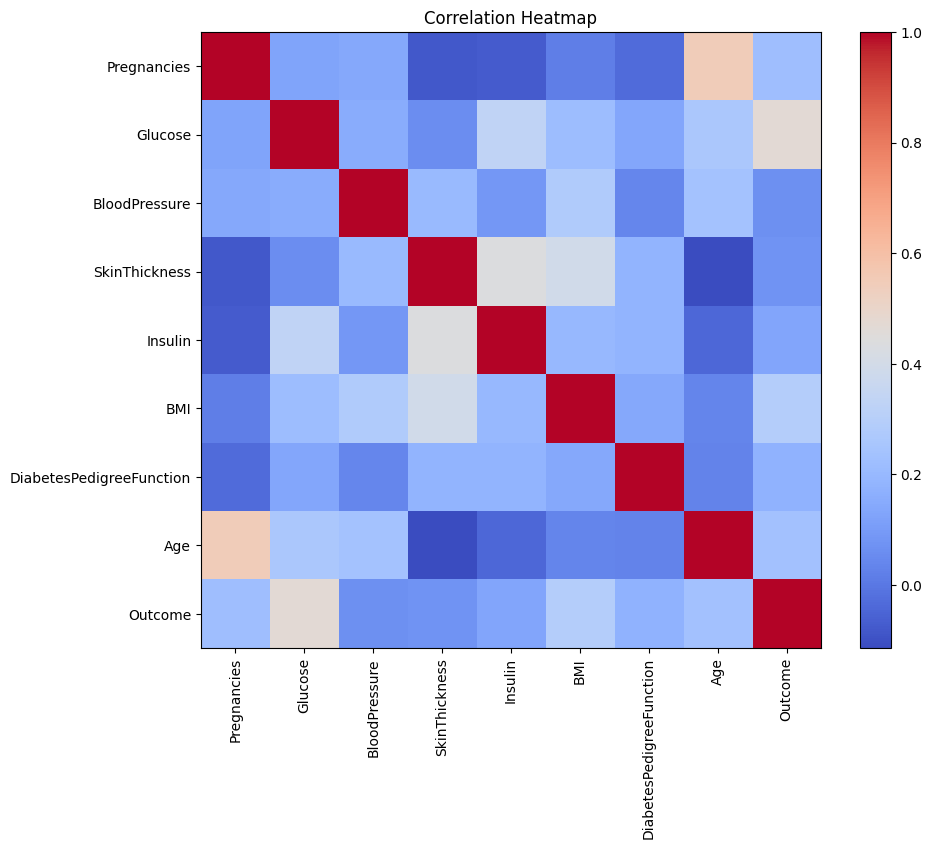

Pregnancies = 4 outliers
Glucose = 5 outliers
BloodPressure = 45 outliers
SkinThickness = 1 outliers
Insulin = 34 outliers
BMI = 19 outliers
DiabetesPedigreeFunction = 29 outliers
Age = 9 outliers
Outcome = 0 outliers

Standardized Data
   Pregnancies   Glucose  BloodPressure  SkinThickness   Insulin       BMI  \
0     0.639947  0.848324       0.149641       0.907270 -0.692891  0.204013   
1    -0.844885 -1.123396      -0.160546       0.530902 -0.692891 -0.684422   
2     1.233880  1.943724      -0.263941      -1.288212 -0.692891 -1.103255   
3    -0.844885 -0.998208      -0.160546       0.154533  0.123302 -0.494043   
4    -1.141852  0.504055      -1.504687       0.907270  0.765836  1.409746   

   DiabetesPedigreeFunction       Age   Outcome  
0                  0.468492  1.425995  1.365896  
1                 -0.365061 -0.190672 -0.732120  
2                  0.604397 -0.105584  1.365896  
3                 -0.920763 -1.041549 -0.732120  
4                  5.484909 -0.020496  1.365

In [ ]:
path="diabetes.csv"
df=pd.read_csv(path)

print(df.head())
print(df.tail())
print(df.shape)
print(df.columns)
print(df.dtypes)
print(df.info())
print(df.describe(include='all'))
print("\nDuplicate Rows :", df.duplicated().sum())
print("\nMISSING VALUES")
missing=pd.DataFrame({"Missing Values": df.isnull().sum(),"Percentage": (df.isnull().sum()/len(df)) * 100})
print(missing)


for col in df.columns:
    if df[col].dtype=="object":
        df[col]=df[col].fillna(df[col].mode()[0])
    else:
        df[col]=df[col].fillna(df[col].median())

print("\nMissing values after preprocessing")
print(df.isnull().sum())

label_encoder=LabelEncoder()
for col in df.select_dtypes(include="object").columns:
    df[col] = label_encoder.fit_transform(df[col])

print("\nCategorical variables encoded.")
numerical=df.select_dtypes(include=np.number).columns
categorical=df.select_dtypes(exclude=np.number).columns

print("\nNumerical Features")
print(numerical)

print("\nCategorical Features")
print(categorical)

for col in numerical:
    plt.figure(figsize=(6, 4))
    plt.hist(df[col], bins=20)
    plt.title(f"Histogram - {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

for col in numerical:
    plt.figure(figsize=(6, 4))
    plt.boxplot(df[col], vert=False)
    plt.title(f"Box Plot - {col}")
    plt.show()

for col in df.columns:
    if df[col].nunique()<=15:
        plt.figure(figsize=(6, 4))
        df[col].value_counts().plot(kind="bar")
        plt.title(f"Bar Chart - {col}")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.show()

if len(numerical)>=2:
    plt.figure(figsize=(6, 5))
    plt.scatter(df[numerical[0]], df[numerical[1]])
    plt.xlabel(numerical[0])
    plt.ylabel(numerical[1])
    plt.title("Scatter Plot")
    plt.show()

corr=df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", aspect="auto")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap")
plt.show()

for col in numerical:
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
    IQR=Q3-Q1
    lower=Q1-1.5*IQR
    upper=Q3+1.5*IQR
    outliers=df[(df[col]<lower)|(df[col]>upper)]
    print(col,"=",len(outliers),"outliers")

standard_scaler = StandardScaler()
standardized=standard_scaler.fit_transform(df[numerical])
standardized_df=pd.DataFrame(standardized,columns=numerical)
print("\nStandardized Data")
print(standardized_df.head())

minmax = MinMaxScaler()
normalized = minmax.fit_transform(df[numerical])
normalized_df = pd.DataFrame(normalized,columns=numerical)
print("\nNormalised Data")
print(normalized_df.head())


   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
      Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  \
145  146            6.7           3.0            5.2           2.3   
146  147            6.3           2.5            5.0           1.9   
147  148            6.5           3.0            5.2           2.0   
148  149            6.2           3.4            5.4           2.3   
149  150            5.9           3.0            5.1           1.8   

            Species  
145  Iris-virginica  
146  Iris-virginica  
147  Iris-virginica  
148  Iris-virginica  
149  Ir

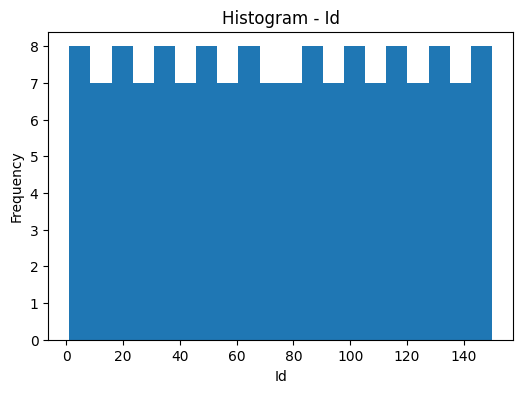

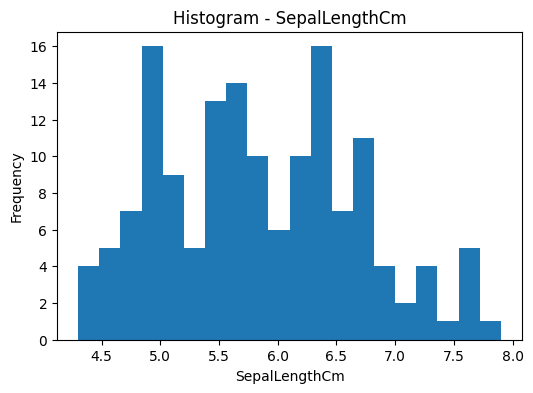

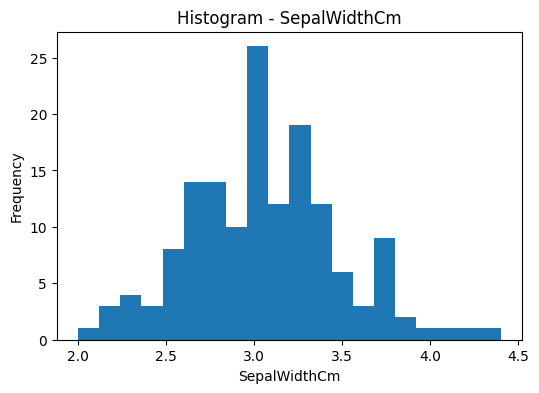

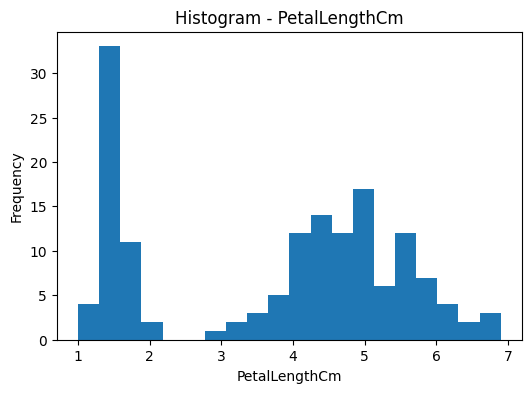

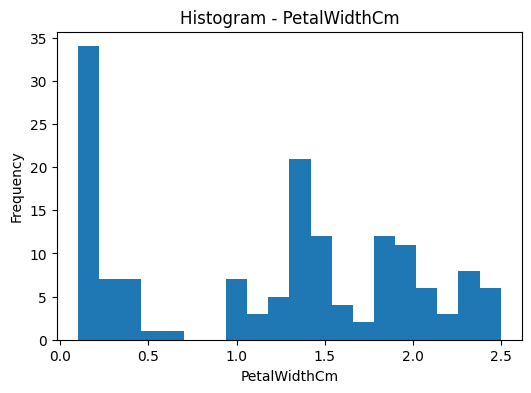

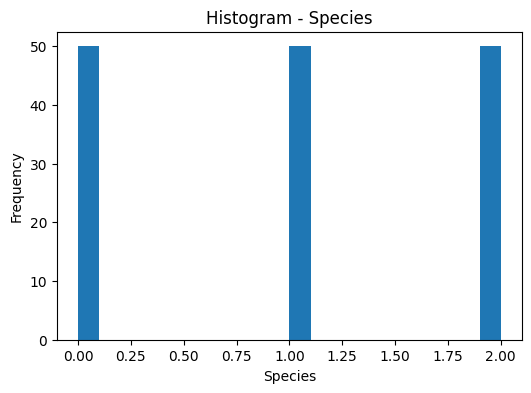

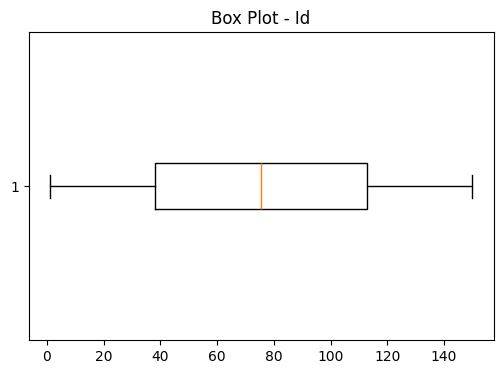

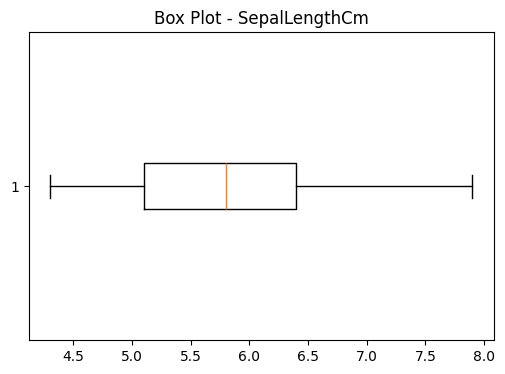

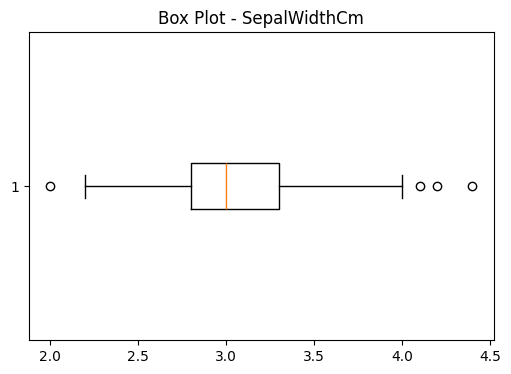

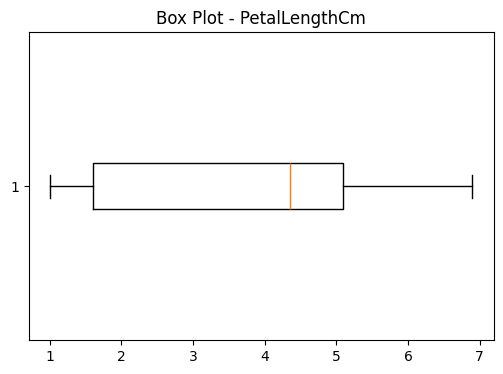

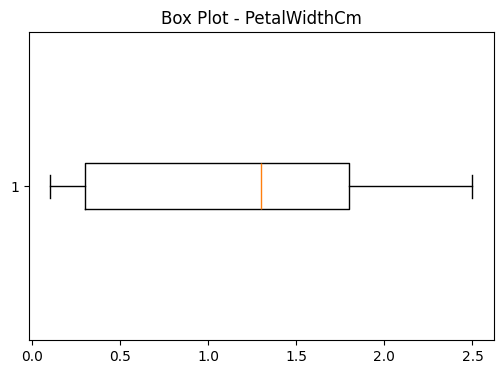

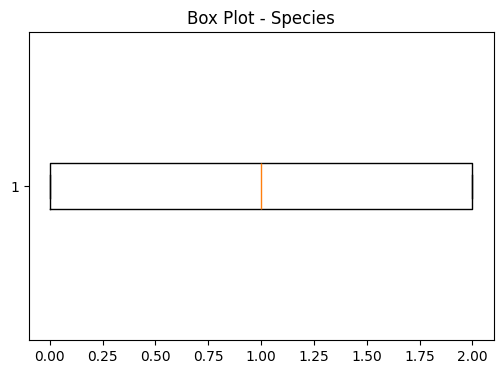

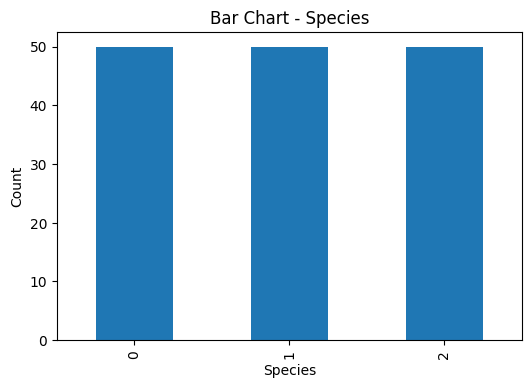

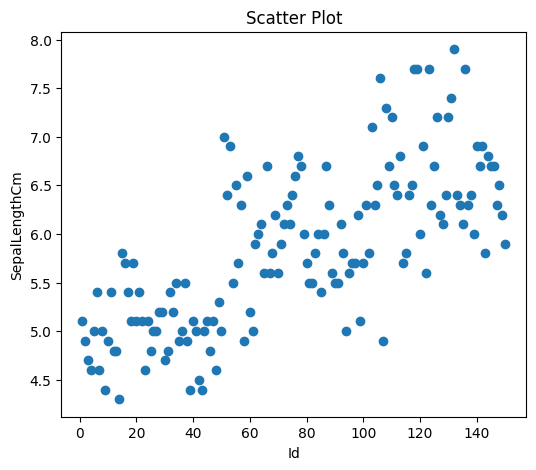

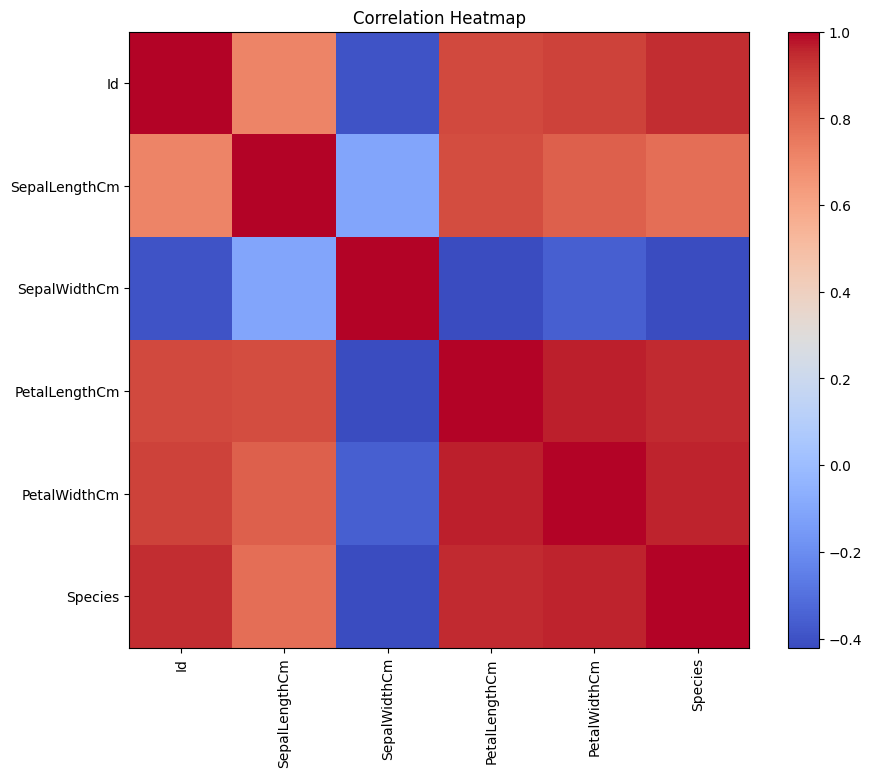

Id = 0 outliers
SepalLengthCm = 0 outliers
SepalWidthCm = 4 outliers
PetalLengthCm = 0 outliers
PetalWidthCm = 0 outliers
Species = 0 outliers

Standardized Data
         Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  \
0 -1.720542      -0.900681      1.032057      -1.341272     -1.312977   
1 -1.697448      -1.143017     -0.124958      -1.341272     -1.312977   
2 -1.674353      -1.385353      0.337848      -1.398138     -1.312977   
3 -1.651258      -1.506521      0.106445      -1.284407     -1.312977   
4 -1.628164      -1.021849      1.263460      -1.341272     -1.312977   

    Species  
0 -1.224745  
1 -1.224745  
2 -1.224745  
3 -1.224745  
4 -1.224745  

Normalised Data
         Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  Species
0  0.000000       0.222222      0.625000       0.067797      0.041667      0.0
1  0.006711       0.166667      0.416667       0.067797      0.041667      0.0
2  0.013423       0.111111      0.500000       0.050847      

In [ ]:
path="Iris.csv"
df=pd.read_csv(path)

print(df.head())
print(df.tail())
print(df.shape)
print(df.columns)
print(df.dtypes)
print(df.info())
print(df.describe(include='all'))
print("\nDuplicate Rows :", df.duplicated().sum())
print("\nMISSING VALUES")
missing=pd.DataFrame({"Missing Values": df.isnull().sum(),"Percentage": (df.isnull().sum()/len(df)) * 100})
print(missing)


for col in df.columns:
    if df[col].dtype=="object":
        df[col]=df[col].fillna(df[col].mode()[0])
    else:
        df[col]=df[col].fillna(df[col].median())

print("\nMissing values after preprocessing")
print(df.isnull().sum())

label_encoder=LabelEncoder()
for col in df.select_dtypes(include="object").columns:
    df[col] = label_encoder.fit_transform(df[col])

print("\nCategorical variables encoded.")
numerical=df.select_dtypes(include=np.number).columns
categorical=df.select_dtypes(exclude=np.number).columns

print("\nNumerical Features")
print(numerical)

print("\nCategorical Features")
print(categorical)

for col in numerical:
    plt.figure(figsize=(6, 4))
    plt.hist(df[col], bins=20)
    plt.title(f"Histogram - {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

for col in numerical:
    plt.figure(figsize=(6, 4))
    plt.boxplot(df[col], vert=False)
    plt.title(f"Box Plot - {col}")
    plt.show()

for col in df.columns:
    if df[col].nunique()<=15:
        plt.figure(figsize=(6, 4))
        df[col].value_counts().plot(kind="bar")
        plt.title(f"Bar Chart - {col}")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.show()

if len(numerical)>=2:
    plt.figure(figsize=(6, 5))
    plt.scatter(df[numerical[0]], df[numerical[1]])
    plt.xlabel(numerical[0])
    plt.ylabel(numerical[1])
    plt.title("Scatter Plot")
    plt.show()

corr=df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", aspect="auto")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap")
plt.show()

for col in numerical:
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
    IQR=Q3-Q1
    lower=Q1-1.5*IQR
    upper=Q3+1.5*IQR
    outliers=df[(df[col]<lower)|(df[col]>upper)]
    print(col,"=",len(outliers),"outliers")

standard_scaler = StandardScaler()
standardized=standard_scaler.fit_transform(df[numerical])
standardized_df=pd.DataFrame(standardized,columns=numerical)
print("\nStandardized Data")
print(standardized_df.head())

minmax = MinMaxScaler()
normalized = minmax.fit_transform(df[numerical])
normalized_df = pd.DataFrame(normalized,columns=numerical)
print("\nNormalised Data")
print(normalized_df.head())


     v1                                                 v2 Unnamed: 2  \
0   ham  Go until jurong point, crazy.. Available only ...        NaN   
1   ham                      Ok lar... Joking wif u oni...        NaN   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...        NaN   
3   ham  U dun say so early hor... U c already then say...        NaN   
4   ham  Nah I don't think he goes to usf, he lives aro...        NaN   

  Unnamed: 3 Unnamed: 4  
0        NaN        NaN  
1        NaN        NaN  
2        NaN        NaN  
3        NaN        NaN  
4        NaN        NaN  
        v1                                                 v2 Unnamed: 2  \
5567  spam  This is the 2nd time we have tried 2 contact u...        NaN   
5568   ham              Will Ì_ b going to esplanade fr home?        NaN   
5569   ham  Pity, * was in mood for that. So...any other s...        NaN   
5570   ham  The guy did some bitching but I acted like i'd...        NaN   
5571   ham               

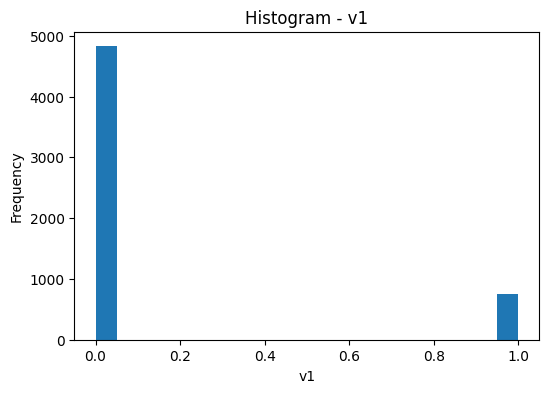

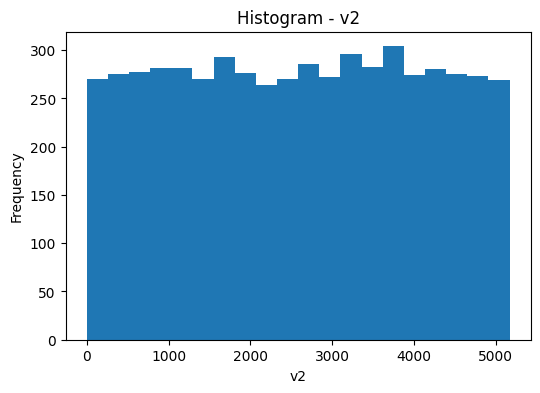

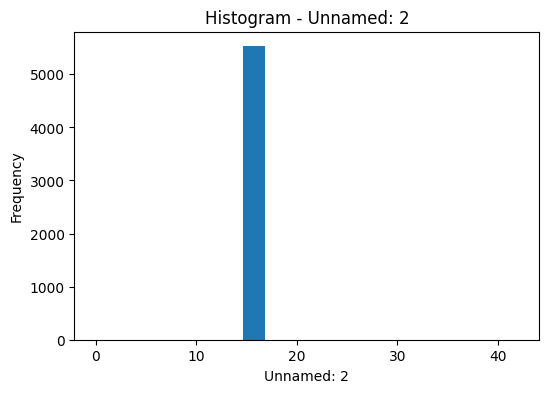

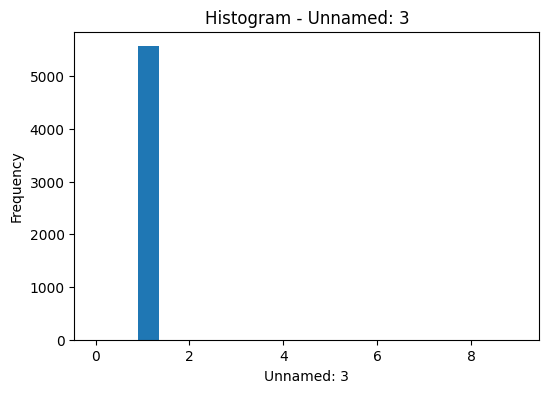

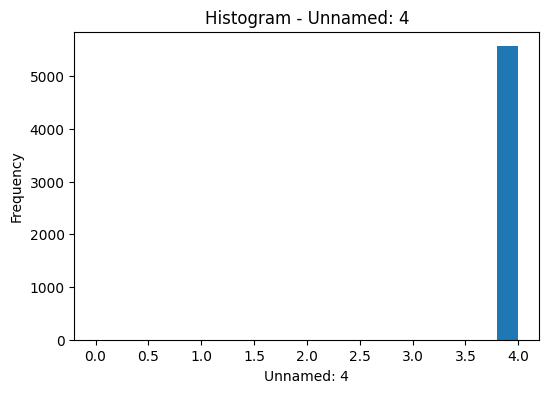

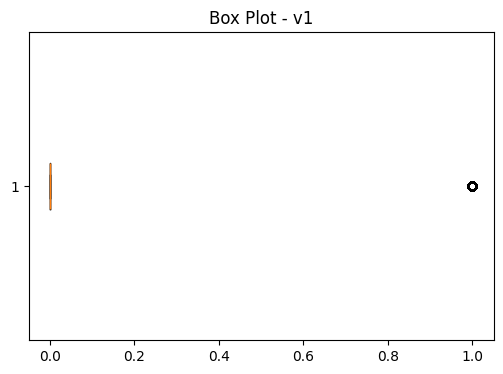

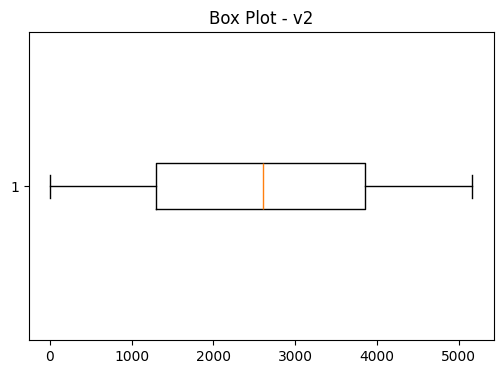

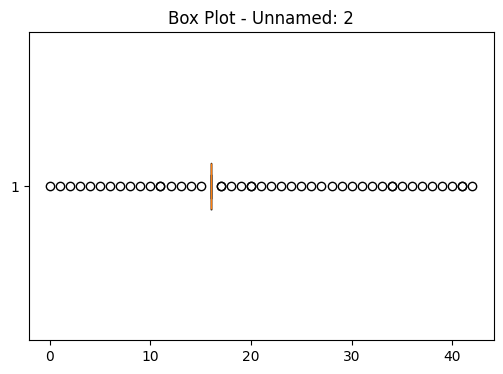

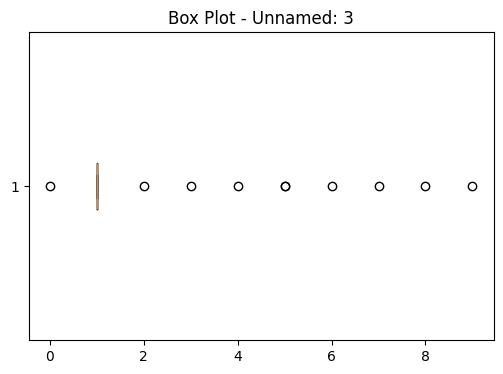

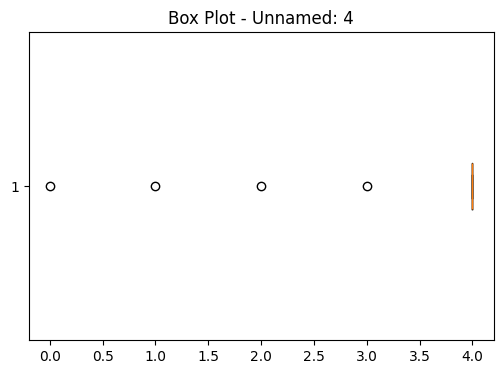

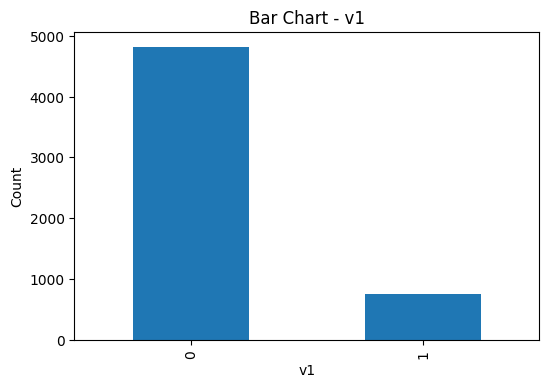

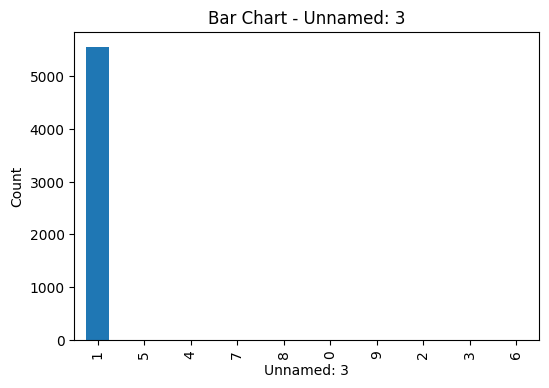

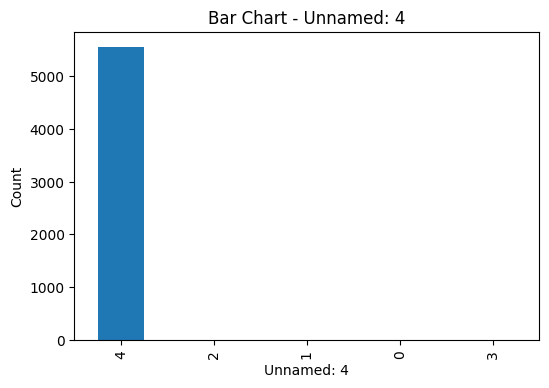

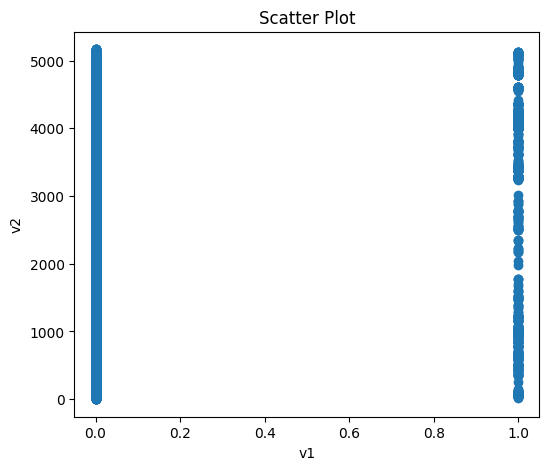

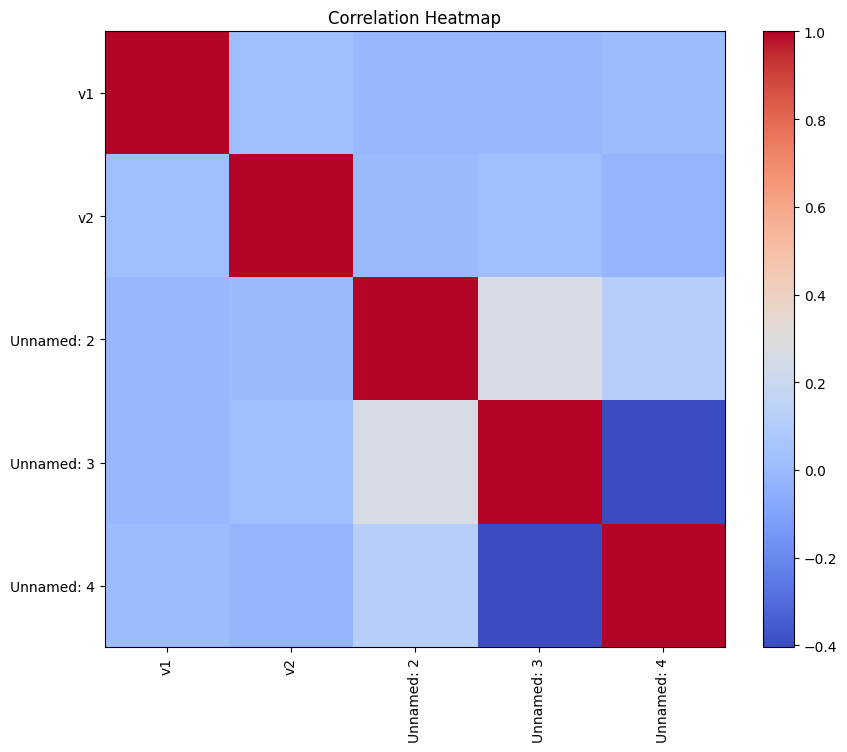

v1 = 747 outliers
v2 = 0 outliers
Unnamed: 2 = 47 outliers
Unnamed: 3 = 10 outliers
Unnamed: 4 = 4 outliers

Standardized Data
        v1        v2  Unnamed: 2  Unnamed: 3  Unnamed: 4
0 -0.39347 -1.016908   -0.037107   -0.035167    0.024466
1 -0.39347  0.345511   -0.037107   -0.035167    0.024466
2  2.54149 -1.070138   -0.037107   -0.035167    0.024466
3 -0.39347  1.010549   -0.037107   -0.035167    0.024466
4 -0.39347  0.113725   -0.037107   -0.035167    0.024466

Normalised Data
    v1        v2  Unnamed: 2  Unnamed: 3  Unnamed: 4
0  0.0  0.208785    0.380952    0.111111         1.0
1  0.0  0.600039    0.380952    0.111111         1.0
2  1.0  0.193498    0.380952    0.111111         1.0
3  0.0  0.791022    0.380952    0.111111         1.0
4  0.0  0.533475    0.380952    0.111111         1.0


In [ ]:
path="spam.csv"
df=pd.read_csv(path, encoding="latin-1")

print(df.head())
print(df.tail())
print(df.shape)
print(df.columns)
print(df.dtypes)
print(df.info())
print(df.describe(include='all'))
print("\nDuplicate Rows :", df.duplicated().sum())
print("\nMISSING VALUES")
missing=pd.DataFrame({"Missing Values": df.isnull().sum(),"Percentage": (df.isnull().sum()/len(df)) * 100})
print(missing)


for col in df.columns:
    if df[col].dtype=="object":
        df[col]=df[col].fillna(df[col].mode()[0])
    else:
        df[col]=df[col].fillna(df[col].median())

print("\nMissing values after preprocessing")
print(df.isnull().sum())

label_encoder=LabelEncoder()
for col in df.select_dtypes(include="object").columns:
    df[col] = label_encoder.fit_transform(df[col])

print("\nCategorical variables encoded.")
numerical=df.select_dtypes(include=np.number).columns
categorical=df.select_dtypes(exclude=np.number).columns

print("\nNumerical Features")
print(numerical)

print("\nCategorical Features")
print(categorical)

for col in numerical:
    plt.figure(figsize=(6, 4))
    plt.hist(df[col], bins=20)
    plt.title(f"Histogram - {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

for col in numerical:
    plt.figure(figsize=(6, 4))
    plt.boxplot(df[col], vert=False)
    plt.title(f"Box Plot - {col}")
    plt.show()

for col in df.columns:
    if df[col].nunique()<=15:
        plt.figure(figsize=(6, 4))
        df[col].value_counts().plot(kind="bar")
        plt.title(f"Bar Chart - {col}")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.show()

if len(numerical)>=2:
    plt.figure(figsize=(6, 5))
    plt.scatter(df[numerical[0]], df[numerical[1]])
    plt.xlabel(numerical[0])
    plt.ylabel(numerical[1])
    plt.title("Scatter Plot")
    plt.show()

corr=df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", aspect="auto")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap")
plt.show()

for col in numerical:
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
    IQR=Q3-Q1
    lower=Q1-1.5*IQR
    upper=Q3+1.5*IQR
    outliers=df[(df[col]<lower)|(df[col]>upper)]
    print(col,"=",len(outliers),"outliers")

standard_scaler = StandardScaler()
standardized=standard_scaler.fit_transform(df[numerical])
standardized_df=pd.DataFrame(standardized,columns=numerical)
print("\nStandardized Data")
print(standardized_df.head())

minmax = MinMaxScaler()
normalized = minmax.fit_transform(df[numerical])
normalized_df = pd.DataFrame(normalized,columns=numerical)
print("\nNormalised Data")
print(normalized_df.head())


   label  1x1  1x2  1x3  1x4  1x5  1x6  1x7  1x8  1x9  ...  28x19  28x20  \
0      5    0    0    0    0    0    0    0    0    0  ...      0      0   
1      0    0    0    0    0    0    0    0    0    0  ...      0      0   
2      4    0    0    0    0    0    0    0    0    0  ...      0      0   
3      1    0    0    0    0    0    0    0    0    0  ...      0      0   
4      9    0    0    0    0    0    0    0    0    0  ...      0      0   

   28x21  28x22  28x23  28x24  28x25  28x26  28x27  28x28  
0      0      0      0      0      0      0      0      0  
1      0      0      0      0      0      0      0      0  
2      0      0      0      0      0      0      0      0  
3      0      0      0      0      0      0      0      0  
4      0      0      0      0      0      0      0      0  

[5 rows x 785 columns]
       label  1x1  1x2  1x3  1x4  1x5  1x6  1x7  1x8  1x9  ...  28x19  28x20  \
59995      8    0    0    0    0    0    0    0    0    0  ...      0      0   

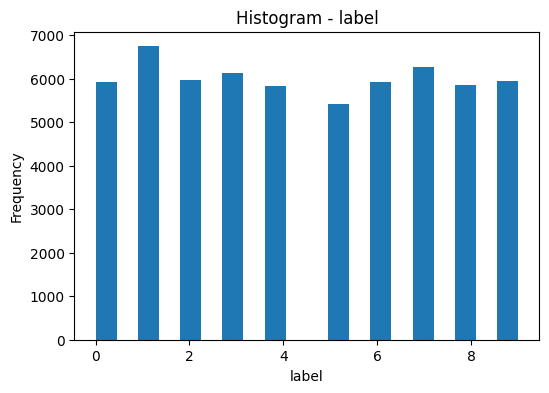

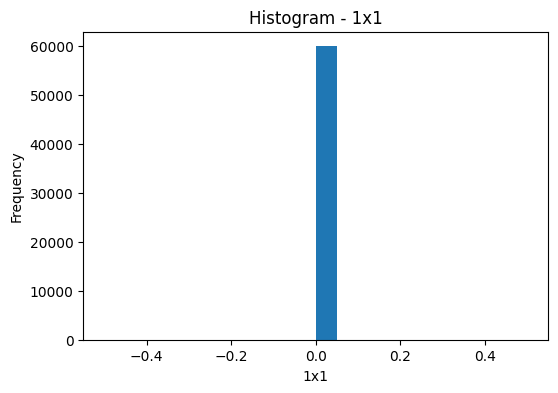

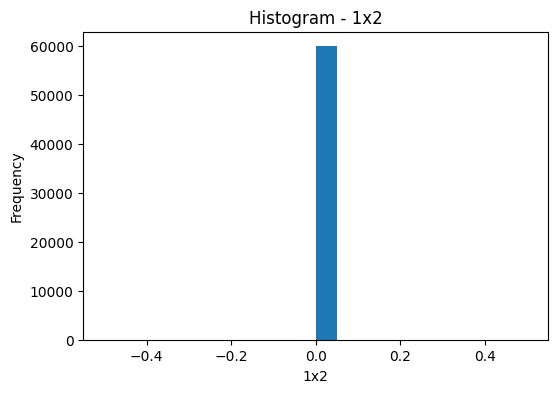

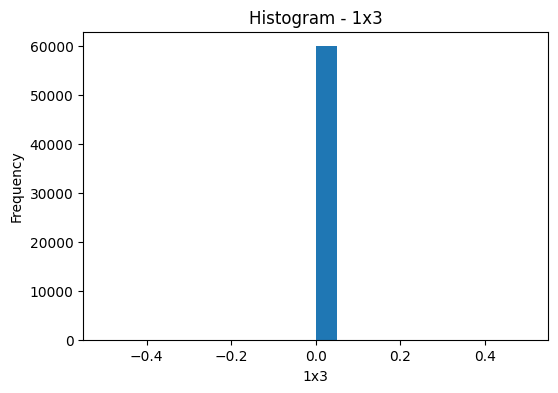

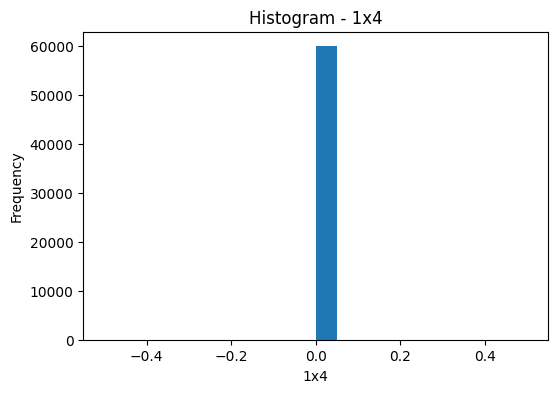

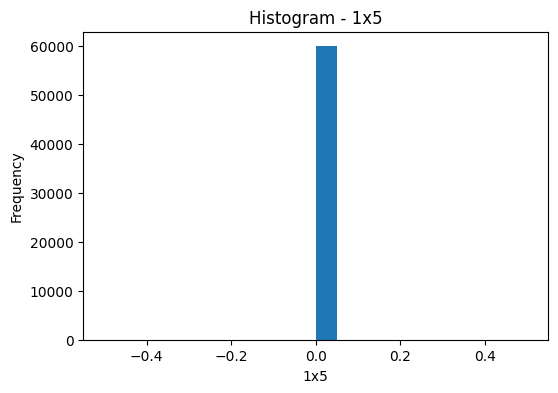

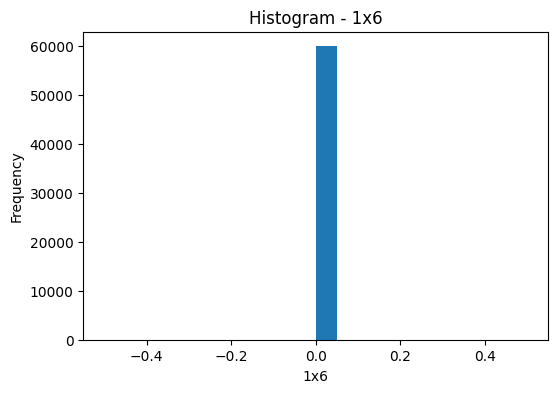

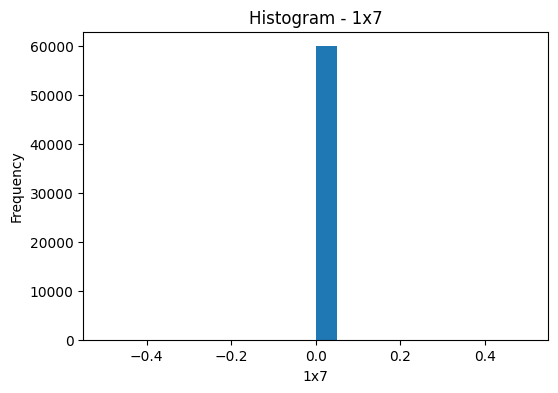

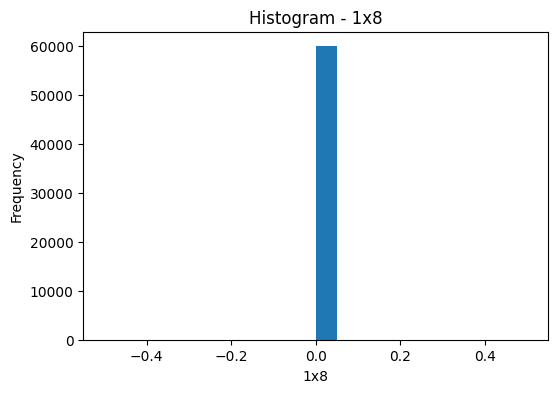

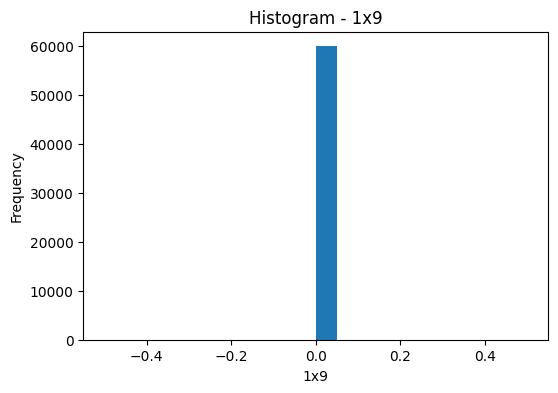

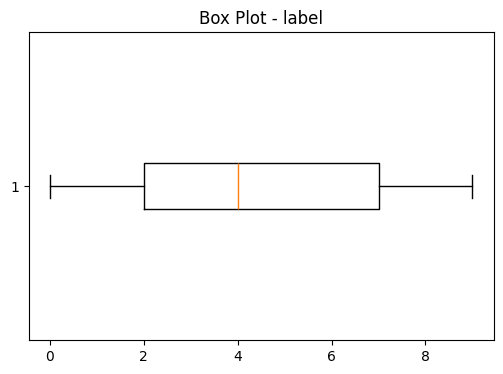

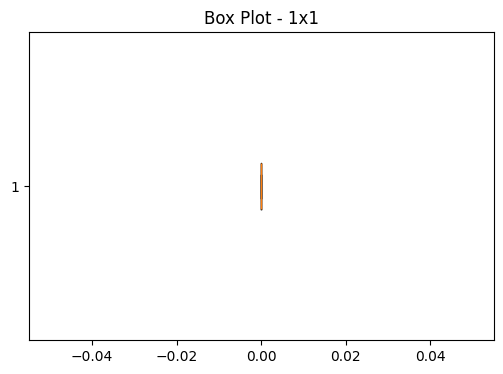

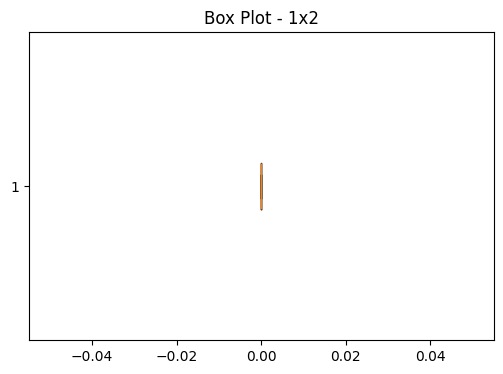

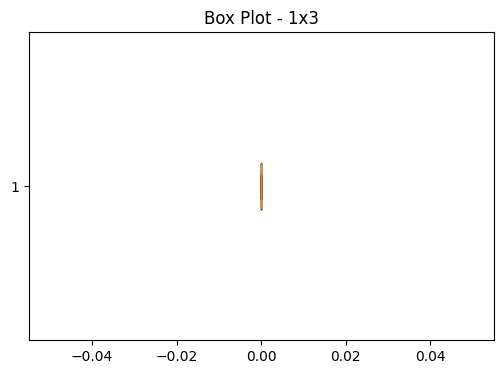

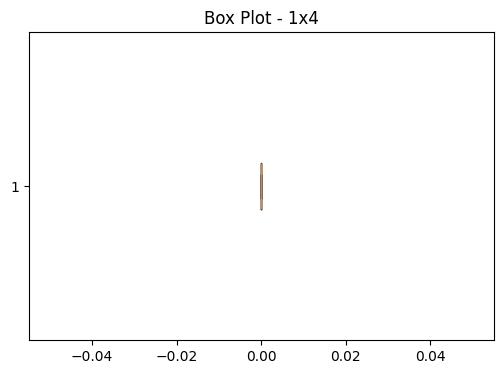

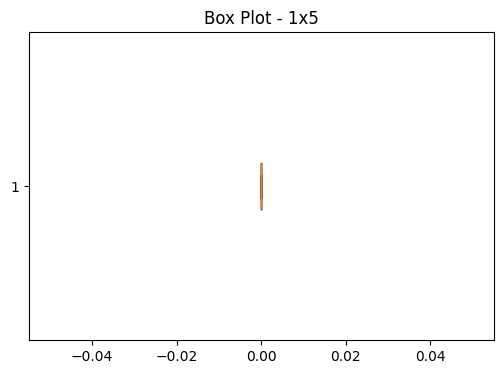

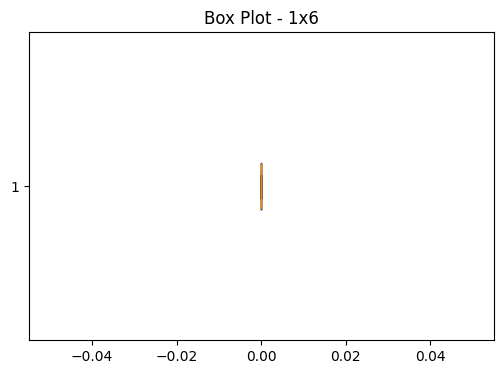

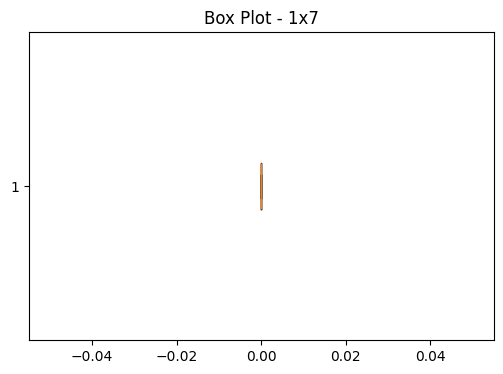

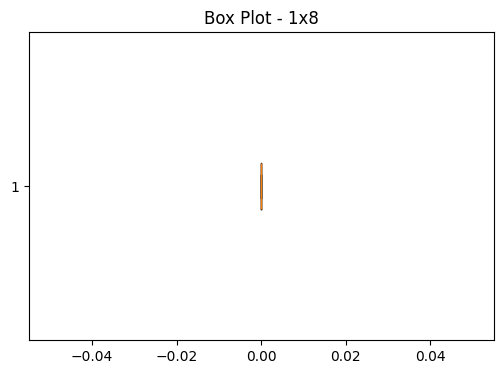

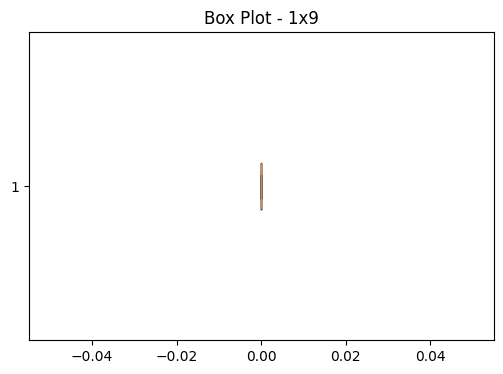

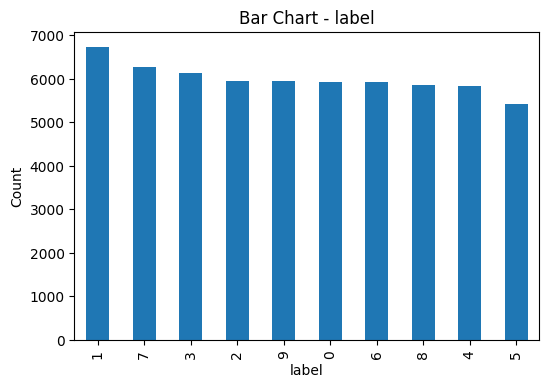

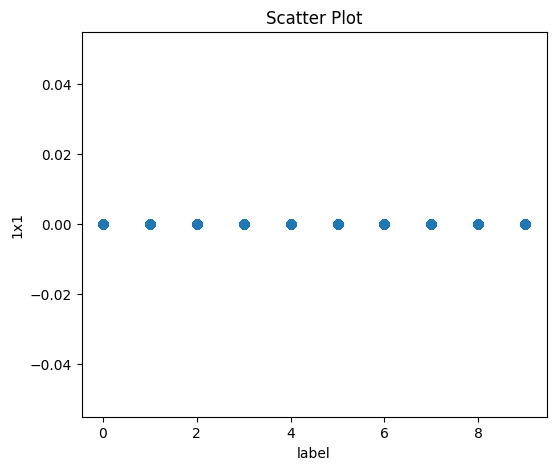

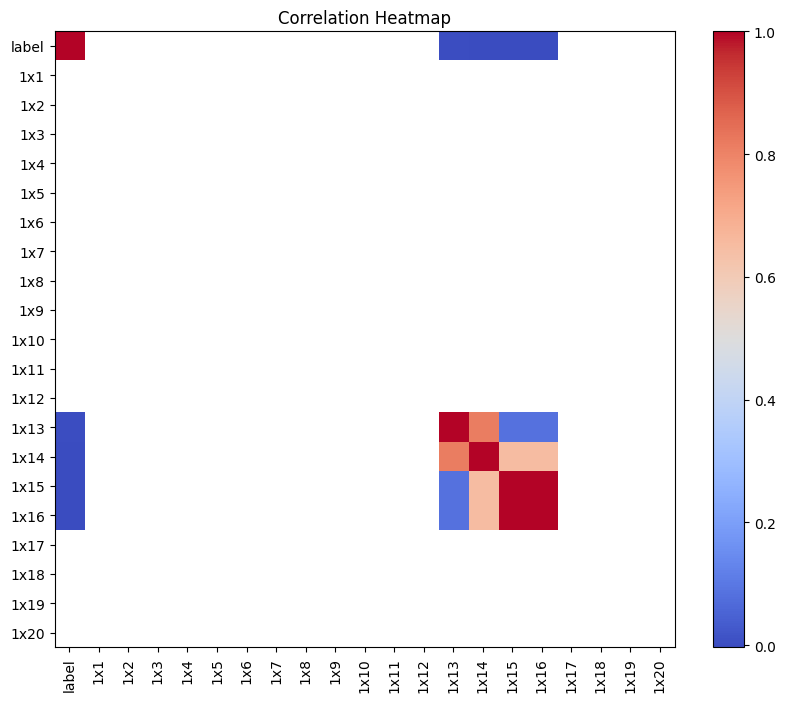

label = 0 outliers
1x1 = 0 outliers
1x2 = 0 outliers
1x3 = 0 outliers
1x4 = 0 outliers
1x5 = 0 outliers
1x6 = 0 outliers
1x7 = 0 outliers
1x8 = 0 outliers
1x9 = 0 outliers

Standardized Data
      label  1x1  1x2  1x3  1x4  1x5  1x6  1x7  1x8  1x9  ...     28x19  \
0  0.189000  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ... -0.033171   
1 -1.541555  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ... -0.033171   
2 -0.157111  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ... -0.033171   
3 -1.195444  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ... -0.033171   
4  1.573444  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ... -0.033171   

      28x20     28x21     28x22     28x23    28x24  28x25  28x26  28x27  28x28  
0 -0.022463 -0.016069 -0.011432 -0.009007 -0.00577    0.0    0.0    0.0    0.0  
1 -0.022463 -0.016069 -0.011432 -0.009007 -0.00577    0.0    0.0    0.0    0.0  
2 -0.022463 -0.016069 -0.011432 -0.009007 -0.00577    0.0    0.0    0.0    0.0  
3 -0.022463 -0.016069 -0.011432 -0

In [ ]:
path="mnist_train.csv"
df=pd.read_csv(path)

print(df.head())
print(df.tail())
print(df.shape)
print(df.columns)
print(df.dtypes)
print(df.info())
print(df.describe(include='all'))
print("\nDuplicate Rows :", df.duplicated().sum())
print("\nMISSING VALUES")
missing=pd.DataFrame({"Missing Values": df.isnull().sum(),"Percentage": (df.isnull().sum()/len(df)) * 100})
print(missing)


for col in df.columns:
    if df[col].dtype=="object":
        df[col]=df[col].fillna(df[col].mode()[0])
    else:
        df[col]=df[col].fillna(df[col].median())

print("\nMissing values after preprocessing")
print(df.isnull().sum())

label_encoder=LabelEncoder()
for col in df.select_dtypes(include="object").columns:
    df[col] = label_encoder.fit_transform(df[col])

print("\nCategorical variables encoded.")
numerical=df.select_dtypes(include=np.number).columns
categorical=df.select_dtypes(exclude=np.number).columns

print("\nNumerical Features")
print(numerical)

print("\nCategorical Features")
print(categorical)

for col in numerical[:10]:
    plt.figure(figsize=(6, 4))
    plt.hist(df[col], bins=20)
    plt.title(f"Histogram - {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

for col in numerical[:10]:
    plt.figure(figsize=(6, 4))
    plt.boxplot(df[col], vert=False)
    plt.title(f"Box Plot - {col}")
    plt.show()

for col in ["label"]:
    if col in df.columns:
        plt.figure(figsize=(6, 4))
        df[col].value_counts().plot(kind="bar")
        plt.title(f"Bar Chart - {col}")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.show()

if len(numerical)>=2:
    plt.figure(figsize=(6, 5))
    plt.scatter(df[numerical[0]], df[numerical[1]])
    plt.xlabel(numerical[0])
    plt.ylabel(numerical[1])
    plt.title("Scatter Plot")
    plt.show()

corr=df[df.columns[:21]].corr(numeric_only=True)
plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", aspect="auto")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap")
plt.show()

for col in numerical[:10]:
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
    IQR=Q3-Q1
    lower=Q1-1.5*IQR
    upper=Q3+1.5*IQR
    outliers=df[(df[col]<lower)|(df[col]>upper)]
    print(col,"=",len(outliers),"outliers")

standard_scaler = StandardScaler()
standardized=standard_scaler.fit_transform(df[numerical])
standardized_df=pd.DataFrame(standardized,columns=numerical)
print("\nStandardized Data")
print(standardized_df.head())

minmax = MinMaxScaler()
normalized = minmax.fit_transform(df[numerical])
normalized_df = pd.DataFrame(normalized,columns=numerical)
print("\nNormalised Data")
print(normalized_df.head())